# 01 — Exploración de datos

**Proyecto:** Detección de fraude en transacciones bancarias (Tema 12) — IA 2026-2, UBB

**Objetivo del notebook:** conocer el dataset antes de entrenar nada: tamaño, tipos de variables,
nulos, duplicados, desbalance de clases y cómo se comportan `Amount` y `Time` en fraudes y legítimas.
Lo que se decida aquí (por ejemplo, eliminar duplicados) queda en `src/datos.py` para que el baseline y
los modelos usen exactamente los mismos datos.

**Datos:** Credit Card Fraud Detection, Machine Learning Group (ULB), Kaggle. Licencia ODbL.
Dal Pozzolo et al. (2015).

> ⚠️ Ejercicio académico: los resultados no constituyen una decisión sobre clientes reales.


## 0. Preparación del entorno

**Objetivo:** importamos las librerías y la configuración común del proyecto (`src/config.py`).

**Fundamento:** la semilla, las rutas y el nombre de la columna objetivo se definen en un solo lugar.
Si cada notebook los escribiera a mano, podrían quedar distintos sin darnos cuenta.
Como el notebook está en `notebooks/`, agregamos la raíz del proyecto al `sys.path` para poder importar `src`.


In [1]:
import sys
from pathlib import Path

# Buscar la raíz del proyecto (la carpeta que contiene src/) para poder importar nuestros módulos
RAIZ = Path.cwd()
while not (RAIZ / "src").exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import RANDOM_STATE, RUTA_CSV, DIR_CAPTURAS, COLUMNA_OBJETIVO
from src.datos import cargar_datos, eliminar_duplicados, resumen_clases

# Colores fijos para las dos clases en TODOS los gráficos (azul = legítima, naranjo = fraude)
COLORES = {0: "#2a78d6", 1: "#eb6834"}
NOMBRES = {0: "Legítima", 1: "Fraude"}

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)
DIR_CAPTURAS.mkdir(parents=True, exist_ok=True)

print("Raíz del proyecto:", RAIZ)
print("Semilla:", RANDOM_STATE)

Raíz del proyecto: C:\Users\canto\.gemini\antigravity\scratch\ProyectoIA-fraude
Semilla: 42


## 1. Carga, tamaño y tipos de variables

**Objetivo:** cargamos el CSV **original** (todavía sin quitar duplicados, para poder analizarlos
en la sección 2) y revisamos cuántas filas y columnas tiene y de qué tipo es cada una.

**Fundamento:** hay que confirmar que el archivo descargado es el esperado (284.807 filas, 31 columnas)
y que todas las variables son numéricas. Si hubiera texto o categorías, habría que codificarlas antes de
entrenar.


In [2]:
df_original = cargar_datos(quitar_duplicados=False)

print("Filas, columnas:", df_original.shape)
df_original.head()

Filas, columnas: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
# Tipos de dato: cuántas columnas hay de cada tipo
print(df_original.dtypes.value_counts())
print()
print("Columnas:", list(df_original.columns))

float64    30
int64       1
Name: count, dtype: int64

Columnas: ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']


In [4]:
# Estadísticas básicas de las columnas que SÍ son interpretables
df_original[["Time", "Amount", "Class"]].describe().round(2)

,Time,Amount,Class
count,284807.00,284807.00,284807.00
mean,94813.86,88.35,0.00
std,47488.15,250.12,0.04
min,0.00,0.00,0.00
25%,54201.50,5.60,0.00
50%,84692.00,22.00,0.00
75%,139320.50,77.16,0.00
max,172792.00,25691.16,1.00


**Lectura:**
- `Time`: segundos transcurridos desde la primera transacción del dataset (cubre unos 2 días).
- `V1`–`V28`: componentes principales (PCA) que el banco entregó así por confidencialidad. **No son
  interpretables**: no sabemos qué variable original representa cada una.
- `Amount`: monto de la transacción (en euros, según la descripción del dataset).
- `Class`: 1 = fraude, 0 = legítima.

**Consideraciones sobre las variables:**
- **Componentes PCA (V1–V28):** Corresponden a transformaciones lineales ortogonales aplicadas por la entidad emisora para proteger la confidencialidad de los usuarios. Poseen capacidad predictiva pero carecen de semántica de negocio directa.
- **Variables no transformadas (Time y Amount):** Mantienen sus magnitudes numéricas originales (Amount alcanza montos elevados). Requieren escalado con `StandardScaler` dentro del pipeline para no sesgar algoritmos sensibles a la escala como la regresión logística.

## 2. Valores nulos y filas duplicadas

**Objetivo:** contamos valores faltantes y filas repetidas, y vemos de qué clase son los duplicados.

**Fundamento:** los nulos rompen el entrenamiento o obligan a imputar. Los duplicados son un problema más
sutil: si una fila queda en entrenamiento y su copia exacta en prueba, el modelo es evaluado con una
transacción que ya "memorizó" (**fuga de información**) y las métricas salen mejores de lo que son.


In [5]:
nulos = df_original.isna().sum()
print("Total de valores nulos:", int(nulos.sum()))
print("Columnas con nulos:", list(nulos[nulos > 0].index) or "ninguna")

Total de valores nulos: 0
Columnas con nulos: ninguna


In [6]:
# duplicated() marca como True las COPIAS (deja sin marcar la primera aparición)
duplicados = df_original[df_original.duplicated(keep="first")]
print("Filas duplicadas (copias):", len(duplicados))
print()
print("Clase de los duplicados:")
print(duplicados[COLUMNA_OBJETIVO].map(NOMBRES).value_counts())

# Verificación: ¿hay filas con las mismas variables pero distinta etiqueta?
# Si este número fuera mayor que el anterior, habría transacciones idénticas etiquetadas de dos formas.
dup_sin_clase = df_original.drop(columns=COLUMNA_OBJETIVO).duplicated(keep="first").sum()
print()
print("Duplicados mirando solo las variables (sin Class):", dup_sin_clase)

Filas duplicadas (copias): 1081

Clase de los duplicados:
Class
Legítima    1062
Fraude        19
Name: count, dtype: int64

Duplicados mirando solo las variables (sin Class): 1081


In [7]:
# Eliminación con la función reutilizable de src/datos.py (la misma que usarán el baseline y los modelos)
df = eliminar_duplicados(df_original, verbose=True)

Filas duplicadas a eliminar: 1081
  - legítimas: 1062
  - fraudes:   19
Antes:   284807 filas, 492 fraudes (0.173%)
Después: 283726 filas, 473 fraudes (0.167%)


### Decisión: eliminar los duplicados antes de la partición

Según las salidas anteriores:
- El dataset no tiene valores nulos, así que no hay que imputar nada.
- Hay **1.081 filas que son copias exactas** de otra (mismas 31 columnas): **1.062 legítimas y 19 fraudes**.
- No hay transacciones idénticas con etiquetas distintas: los duplicados no son contradictorios.
- Tras eliminarlos quedan **283.726 transacciones, de las cuales 473 son fraude (0,167 %)**.
  Antes eran 492 fraudes (0,173 %).

**Decidimos eliminarlos, conservando la primera aparición, y hacerlo antes de partir en train/val/test.**

Justificación:
1. **Evitar fuga de información.** Con la partición aleatoria 70/15/15, una copia podría quedar en
   entrenamiento y otra en prueba, y el modelo sería evaluado con datos que ya vio, lo que inflaría
   la AUPRC, la precisión y el recall. Esto pesa más en los fraudes: con tan pocos casos, cada fraude repetido
   que se "filtra" a prueba cambia bastante el recall.
2. **Costo bajo.** Se pierde el 0,38 % de las filas. El desbalance casi no cambia (de 0,173 % a 0,167 %).
3. **Reproducibilidad.** La eliminación está en `src/datos.py` (`cargar_datos()` la aplica por defecto).
   El baseline, los modelos y la interfaz cargan exactamente las mismas 283.726 filas.

Limitación: no sabemos si las copias son errores de registro o transacciones reales repetidas (por ejemplo,
un doble cobro). Coincidir en las 28 componentes PCA, el monto y el segundo exacto es muy improbable
entre transacciones distintas, así que las tratamos como registros repetidos.

**A partir de aquí, todo el notebook usa `df` (sin duplicados).**


**Justificación metodológica del tratamiento de duplicados:**
- **Control estricto de Data Leakage:** Si registros exactamente idénticos cayeran en subconjuntos separados tras la partición aleatoria, el evaluador mediría memorización en lugar de capacidad de generalización.
- **Impacto mínimo en la prevalencia:** La remoción de 1.081 duplicados solo reduce los casos positivos de 492 (0,173 %) a 473 (0,167 %) sobre 283.726 registros finales, manteniendo intacta la severidad del desbalance.
- **Eliminación previa a la partición:** Filtrar antes del muestreo asegura matemáticamente que ninguna réplica cruce la frontera entre entrenamiento, validación y prueba.

## 3. Distribución de la clase objetivo (desbalance)

**Objetivo:** contamos fraudes y legítimas, lo graficamos y calculamos la accuracy de un
"modelo" que **nunca** predice fraude.

**Fundamento:** es el centro del problema. Con un desbalance tan grande, la accuracy no sirve como métrica y
hay que usar AUPRC, precisión y recall. Este cálculo es el argumento que vamos a mostrar con el baseline
`DummyClassifier`.


In [8]:
conteo = df[COLUMNA_OBJETIVO].value_counts().sort_index()
tabla_clases = pd.DataFrame({
    "clase": conteo.index.map(NOMBRES),
    "transacciones": conteo.values,
    "porcentaje": (100 * conteo / conteo.sum()).round(3).values,
})
print(tabla_clases.to_string(index=False))
print()
print(f"Razón: 1 fraude por cada {conteo[0] / conteo[1]:.0f} transacciones legítimas")

   clase  transacciones  porcentaje
Legítima         283253      99.833
  Fraude            473       0.167

Razón: 1 fraude por cada 599 transacciones legítimas


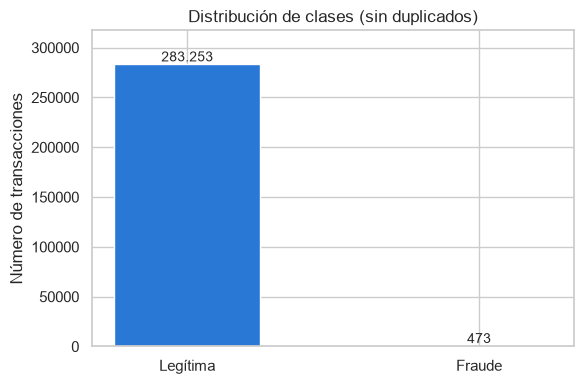

In [9]:
fig, ax = plt.subplots(figsize=(6, 4))
barras = ax.bar(
    [NOMBRES[c] for c in conteo.index], conteo.values,
    color=[COLORES[c] for c in conteo.index], width=0.5,
)
# Escribimos el número sobre cada barra: la de fraude es casi invisible en escala lineal (ese es el punto)
for barra, valor in zip(barras, conteo.values):
    ax.annotate(f"{valor:,}".replace(",", "."), (barra.get_x() + barra.get_width() / 2, valor),
                ha="center", va="bottom", fontsize=10)
ax.set_ylim(0, conteo.max() * 1.12)  # margen arriba para que quepa la etiqueta
ax.set_ylabel("Número de transacciones")
ax.set_title("Distribución de clases (sin duplicados)")
plt.tight_layout()
plt.savefig(DIR_CAPTURAS / "01_distribucion_clases.png", dpi=150)
plt.show()

In [10]:
# Accuracy de un clasificador que SIEMPRE dice "legítima": acierta todas las legítimas y ningún fraude
accuracy_nunca_fraude = conteo[0] / conteo.sum()
print(f"Accuracy de 'nunca fraude': {100 * accuracy_nunca_fraude:.2f}%  ->  recall de fraude = 0%")

Accuracy de 'nunca fraude': 99.83%  ->  recall de fraude = 0%


**Criterio de selección de métricas y manejo del desbalance:**
- **Inadecuación de Accuracy:** Con una prevalencia del 0,167 %, la exactitud global es dominada por la clase mayoritaria; predecir siempre legítima otorga 99,83 % de aciertos teóricos pero con un Recall de 0,0, resultando inoperante.
- **Métricas adoptadas:** Se priorizan Precisión, Recall y el Área bajo la Curva Precisión-Recall (AUPRC), evaluando la capacidad de aislar fraudes minimizando falsas alarmas operativas.
- **Implicancias en el aprendizaje:** Algoritmos estándar tienden a clasificar todo como legítimo al minimizar la pérdida global. Esto fundamenta el uso de partición estratificada obligatoria y sienta las bases para comparar ponderación de clases (`class_weight`) y sobremuestreo (SMOTE) en etapas posteriores.

## 4. Distribución de `Amount` por clase

**Objetivo:** comparamos el monto de las transacciones legítimas y fraudulentas con estadísticas
descriptivas y un histograma.

**Fundamento:** `Amount` es una de las dos variables interpretables. Queremos ver si los fraudes tienen
montos distintos y qué tan sesgada (asimétrica) es la variable, porque eso influye en el escalado.

**Dos decisiones del gráfico:**
- **Escala logarítmica** en el eje x (usamos `log10(Amount + 1)`): hay muchos montos pequeños y pocos
  muy grandes. En escala lineal todo queda aplastado contra el cero. Se suma 1 porque hay montos iguales a 0.
- **Densidad en vez de conteo** (`stat="density", common_norm=False`): cada clase se normaliza por
  separado. Con conteos, los 473 fraudes serían invisibles frente a 283 mil legítimas.


In [11]:
desc_amount = df.groupby(COLUMNA_OBJETIVO)["Amount"].describe().rename(index=NOMBRES)
desc_amount.round(2)

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
Legítima,283253.0,88.41,250.38,0.0,5.67,22.00,77.46,25691.16
Fraude,473.0,123.87,260.21,0.0,1.00,9.82,105.89,2125.87


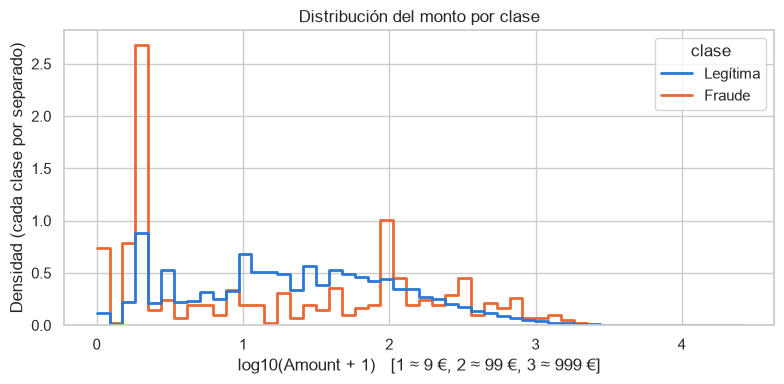

In [12]:
datos_graf = df.assign(
    log_amount=np.log10(df["Amount"] + 1),
    clase=df[COLUMNA_OBJETIVO].map(NOMBRES),
)

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(
    data=datos_graf, x="log_amount", hue="clase", stat="density", common_norm=False,
    bins=50, element="step", fill=False, linewidth=2,
    palette={NOMBRES[0]: COLORES[0], NOMBRES[1]: COLORES[1]}, ax=ax,
)
ax.set_xlabel("log10(Amount + 1)   [1 ≈ 9 €, 2 ≈ 99 €, 3 ≈ 999 €]")
ax.set_ylabel("Densidad (cada clase por separado)")
ax.set_title("Distribución del monto por clase")
plt.tight_layout()
plt.savefig(DIR_CAPTURAS / "01_amount_por_clase.png", dpi=150)
plt.show()

**Interpretación:** La mediana de Amount en fraudes (9,82) es menor que en transacciones legítimas (22,00), evidenciando que los fraudes tienden a concentrarse en montos más bajos (el máximo en fraude es 2.125,87 frente a 25.691,16 en legítimas). Se detectan 25 fraudes con monto 0, consistentes con transacciones de verificación o sondeo de tarjetas activas. Sin embargo, Amount por sí sola no permite una separación nítida debido al alto solapamiento entre distribuciones.

**Notas sobre visualización y preprocesamiento de montos:**
- **Escala logarítmica y densidad:** Permiten visualizar y comparar adecuadamente las curvas amortiguando la fuerte asimetría positiva de los montos (`log10(Amount + 1)`), normalizando las densidades para no eclipsar los 473 fraudes frente a las transacciones legítimas.
- **Ajuste del StandardScaler:** Debe parametrizarse únicamente con los datos de entrenamiento dentro del Pipeline, impidiendo que la media poblacional y dispersión de validación o prueba contaminen el ajuste del modelo.

## 5. Distribución de `Time` por clase

**Objetivo:** pasamos `Time` de segundos a horas y comparamos su distribución en fraudes y legítimas.

**Fundamento:** el dataset cubre unos 2 días. Si la actividad legítima sigue el ciclo día/noche y el fraude
no, la hora podría aportar información. También sirve para decidir si vale la pena transformar `Time`
(por ejemplo, a hora del día) más adelante.


Rango de Time: 0.0 a 48.0 horas


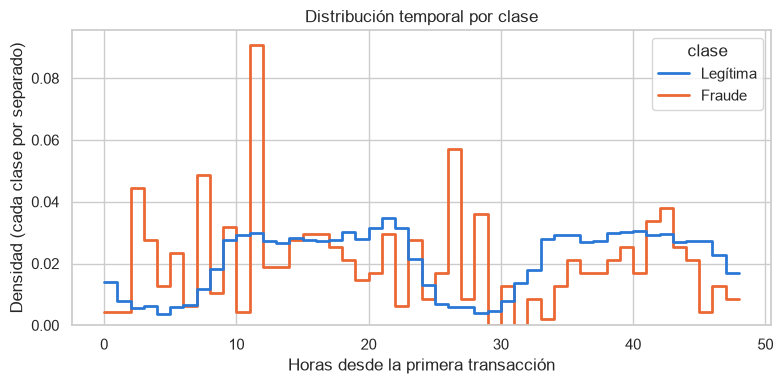

In [13]:
datos_graf["horas"] = df["Time"] / 3600
print(f"Rango de Time: {datos_graf['horas'].min():.1f} a {datos_graf['horas'].max():.1f} horas")

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(
    data=datos_graf, x="horas", hue="clase", stat="density", common_norm=False,
    bins=48, element="step", fill=False, linewidth=2,  # 48 bins = 1 bin por hora
    palette={NOMBRES[0]: COLORES[0], NOMBRES[1]: COLORES[1]}, ax=ax,
)
ax.set_xlabel("Horas desde la primera transacción")
ax.set_ylabel("Densidad (cada clase por separado)")
ax.set_title("Distribución temporal por clase")
plt.tight_layout()
plt.savefig(DIR_CAPTURAS / "01_time_por_clase.png", dpi=150)
plt.show()

**Interpretación:** Se observan dos ciclos diurnos de actividad en las transacciones legítimas, con valles asociados a horarios de madrugada en una ventana de 48 horas continuas. Los fraudes, al constituir un subconjunto reducido (473 eventos), exhiben una dispersión con mayor varianza a lo largo del periodo, sin una periodicidad diurna tan marcada.

**Consideraciones metodológicas sobre la variable temporal:**
- **Naturaleza de Time:** Corresponde a una marca de tiempo relativa en segundos transcurridos desde el inicio de la captura, sin referencia explícita de hora de reloj ni zona horaria.
- **Estrategia de partición:** Se implementa la partición estratificada aleatoria definida en la propuesta inicial para preservar exactamente las proporciones de clase en train, val y test. La validación temporal secuencial queda documentada como una línea de trabajo futuro para escenarios de producción.

## 6. Vistazo rápido a V1–V28

**Objetivo:** calculamos la correlación de cada componente con `Class` y la graficamos ordenada.

**Fundamento:** aunque las V no son interpretables, podemos ver cuáles se relacionan más con el fraude. Esto da
una idea de si un modelo lineal (regresión logística) tiene señal con la que trabajar.

**Limitación:** la correlación de Pearson solo mide relaciones **lineales**. Una variable con correlación
baja aún puede ser útil para un modelo no lineal como Random Forest.


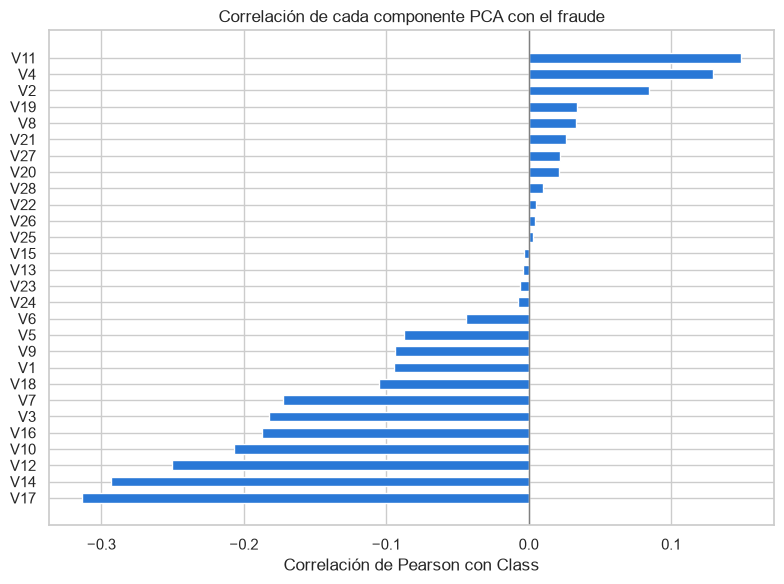

Más negativas: ['V17', 'V14', 'V12']
Más positivas: ['V2', 'V4', 'V11']


In [14]:
columnas_v = [f"V{i}" for i in range(1, 29)]
corr_con_clase = df[columnas_v].corrwith(df[COLUMNA_OBJETIVO]).sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(corr_con_clase.index, corr_con_clase.values, color=COLORES[0], height=0.6)
ax.axvline(0, color="gray", linewidth=1)
ax.set_xlabel("Correlación de Pearson con Class")
ax.set_title("Correlación de cada componente PCA con el fraude")
plt.tight_layout()
plt.savefig(DIR_CAPTURAS / "01_correlacion_v.png", dpi=150)
plt.show()

print("Más negativas:", list(corr_con_clase.index[:3]))
print("Más positivas:", list(corr_con_clase.index[-3:]))

**Interpretación del análisis de correlación:**
- **Utilidad para el baseline lineal:** El ranking de correlaciones lineales (Pearson) identifica componentes con clara señal discriminante hacia la clase positiva (por ejemplo, V17, V14 y V12 con coeficientes negativos; V2, V4 y V11 con coeficientes positivos), justificando la viabilidad del clasificador lineal de referencia.
- **Efecto del desbalance en el coeficiente:** Dada la baja prevalencia del fraude (0,167 %), el coeficiente de Pearson queda matemáticamente restringido a magnitudes reducidas. Valores en torno a |0,30| representan relaciones estadísticas altamente significativas en este régimen.

## 7. Conclusiones de la exploración

1. El dataset final tiene 283.726 transacciones y 473 fraudes (0,167 %) tras eliminar 1.081 filas duplicadas. Se eliminaron antes de la partición para evitar que una copia quedara en entrenamiento y su duplicado en validación o prueba (fuga de información).

2. El desbalance es extremo: 1 fraude por cada ~599 transacciones legítimas. Esto hace que la accuracy sea una métrica engañosa — un modelo que nunca alerta acierta el 99,83 %. Usaremos AUPRC como métrica principal porque mide el desempeño en la clase fraude para todos los umbrales.

3. Amount tiene distribuciones distintas entre clases (mediana 9,82 en fraudes vs 22,00 en legítimas) pero se superponen demasiado para separar solas. Necesita escalado antes de entrar al modelo, que se aplicará dentro del pipeline solo con datos de entrenamiento.

4. Time cubre aproximadamente 48 horas y muestra ciclos de actividad en las legítimas. Los fraudes no muestran un patrón claro, aunque el bajo número de casos hace difícil interpretarlo con certeza.

5. Las componentes con mayor correlación lineal con la clase fraude son V17, V14 y V12 (correlación negativa) y V2, V4 y V11 (correlación positiva). Estas variables aportarán más información al modelo.

6. El siguiente paso es la partición estratificada 70/15/15 y el entrenamiento de los modelos baseline, desarrollados en 02_baseline.ipynb.

Las figuras quedaron guardadas en `docs/capturas/` para el informe y la presentación del Avance 1.
